In [1]:
import torch
import numpy as np
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd

In [2]:
dataset = 'Yahoo'
entity = 'real_65.csv'
injectors = ['GenIAS', 'CARLA', 'NCAD', 'COUTA', 'CutAddPaste']
injections_path = f'/home/zahraz/hz18_scratch/zahraz/gen_anom/generation_metrics/generated_anoms/{dataset}/{entity}'
data = {}
for injector in injectors:
    data[injector] = torch.load(os.path.join(injections_path, f"{injector.lower()}_rep.pth"))['injected_representations'].cpu()

train_test_rep = torch.load(os.path.join(injections_path, "train_test_rep.pth"))
test_representations = train_test_rep["test_representations"]
test_labels = train_test_rep["test_labels"]
test_representations = test_representations[test_labels == 1]

In [14]:
def to_numpy(tensor):
    return tensor.cpu().detach().numpy() if isinstance(tensor, torch.Tensor) else np.array(tensor)

test_representations_np = to_numpy(test_representations)

tsne_results_dict = {}
for name, tensor in data.items():
    tensor_np = to_numpy(tensor)
    
    m = min(len(test_representations_np), len(tensor_np))
    # m = min(m, 1000)
    
    sampled_test_representations = test_representations_np[np.random.choice(len(test_representations_np), m, replace=False)]
    sampled_tensor = tensor_np[np.random.choice(len(tensor_np), m, replace=False)]
    
    combined_data = np.vstack((sampled_test_representations, sampled_tensor))
    
    labels = ['Real'] * m + [name] * m
    
    tsne = TSNE(n_components=2, perplexity=30, random_state=42)
    tsne_results = tsne.fit_transform(combined_data)
    
    df = pd.DataFrame(tsne_results, columns=['TSNE-1', 'TSNE-2'])
    df['Label'] = labels
    tsne_results_dict[name] = df

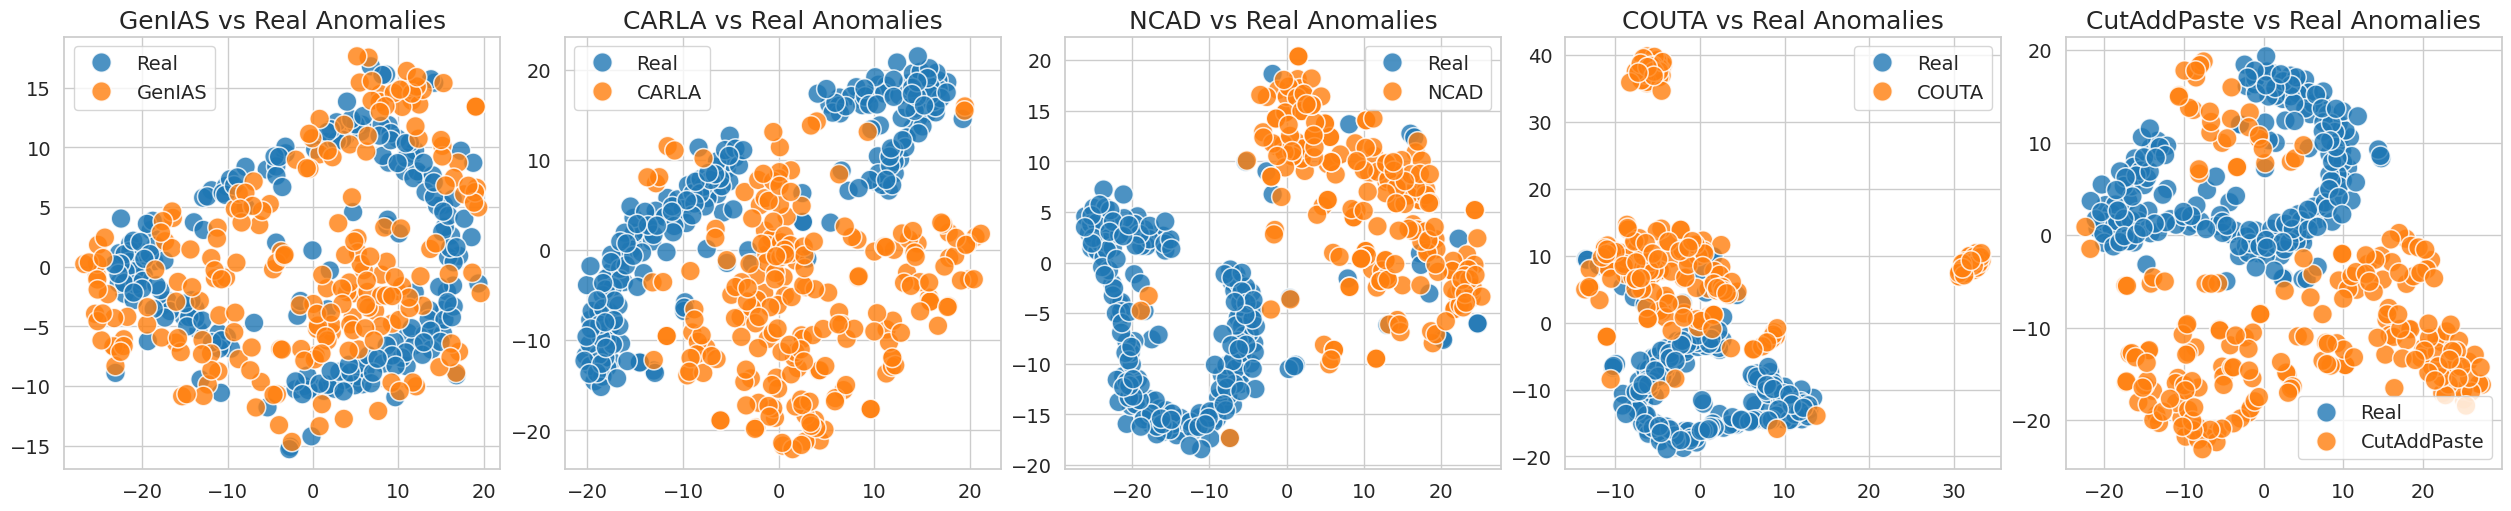

In [16]:
# Plot t-SNE results
num_plots = len(tsne_results_dict)
fig, axes = plt.subplots(1, num_plots, figsize=(5 * num_plots, 5), constrained_layout=True)
sns.set(style="whitegrid")

if num_plots == 1:
    axes = [axes]

for ax, (name, df) in zip(axes, tsne_results_dict.items()):
    sns.scatterplot(x='TSNE-1', y='TSNE-2', hue='Label', data=df, alpha=0.8, palette="tab10", ax=ax, s=200)
    ax.set_title(f'{name} vs Real Anomalies', fontsize=18)
    ax.legend(fontsize=14, loc='best')
    ax.tick_params(axis='both', which='major', labelsize=14)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.show()